# 00 - nuScenes dataset tour (mini)

A hands-on walk through the dataset we use, from raw files up to language annotations. Run the cells top to bottom.

| Part | Question it answers |
|---|---|
| 1 | What is on disk? |
| 2-3 | How are the JSON tables linked? |
| 4-5 | What is a scene, a sample (keyframe) and a sweep? |
| 6-7 | Where are the sensors and what are the coordinate frames? |
| 8-10 | What do camera, LiDAR and radar data look like? |
| 11 | What are the 3D box annotations? |
| 12 | LiDAR + radar + boxes in one picture |
| 13 | Maps, logs, and how weather / lighting can be derived |
| 14 | What does nuScenes-QA look like? |
| 15 | Trace one radar file all the way back to its scene |

**Vocabulary:** *scene* = a 20 s drive. *sample* (keyframe) = a synchronized snapshot at 2 Hz with all sensors and annotations.
*sweep* = a non-keyframe sensor reading (no annotations). *token* = a 32-hex-char ID linking table rows.

In [3]:
%matplotlib inline
import json, sys, collections
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from pyquaternion import Quaternion
from nuscenes.nuscenes import NuScenes
from nuscenes.utils.data_classes import LidarPointCloud, RadarPointCloud

ROOT = Path(r"D:\radar-bev-llm")
DATAROOT = ROOT / "data" / "nuscenes"
sys.path.insert(0, str(ROOT / "code" / "radar"))
from verify_nuscenes_radar import load_radar          # radar points in the ego frame

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 170)
nusc = NuScenes("v1.0-mini", str(DATAROOT), verbose=True)

Loading NuScenes tables for version v1.0-mini...
23 category,
8 attribute,
4 visibility,
911 instance,
12 sensor,
120 calibrated_sensor,
31206 ego_pose,
8 log,
10 scene,
404 sample,
31206 sample_data,
18538 sample_annotation,
4 map,
Done loading in 0.487 seconds.
Reverse indexing ...
Done reverse indexing in 0.1 seconds.


## 1. What is on disk?

Four top-level folders. `samples/` holds the **keyframe** files, `sweeps/` holds the **in-between** readings, `maps/` holds map images, and `v1.0-mini/` holds the JSON tables that describe everything.

In [4]:
def folder_stats(p):
    files = [f for f in p.rglob("*") if f.is_file()]
    return len(files), sum(f.stat().st_size for f in files) / 1e6

rows = []
for top in ["maps", "samples", "sweeps", "v1.0-mini"]:
    n, mb = folder_stats(DATAROOT / top)
    rows.append(dict(folder=top, files=n, MB=round(mb)))
display(pd.DataFrame(rows))

rows = []
for ch in sorted(p.name for p in (DATAROOT / "samples").iterdir()):
    ks = list((DATAROOT / "samples" / ch).iterdir())
    sw = list((DATAROOT / "sweeps" / ch).iterdir())
    rows.append(dict(channel=ch, ext="".join(ks[0].suffixes), keyframe_files=len(ks), sweep_files=len(sw),
                     avg_KB=round(np.mean([f.stat().st_size for f in ks]) / 1e3, 1)))
display(pd.DataFrame(rows))
print("Example file:", next((DATAROOT / "samples" / "RADAR_FRONT").iterdir()).name)

,folder,files,MB
0,maps,4,6
1,samples,4848,728
2,sweeps,26358,4608
3,v1.0-mini,13,33


,channel,ext,keyframe_files,sweep_files,avg_KB
0,CAM_BACK,.jpg,404,1911,161.2
1,CAM_BACK_LEFT,.jpg,404,1923,174.3
2,CAM_BACK_RIGHT,.jpg,404,1938,184.3
3,CAM_FRONT,.jpg,404,1938,180.4
4,CAM_FRONT_LEFT,.jpg,404,1940,182.1
5,CAM_FRONT_RIGHT,.jpg,404,1934,187.2
6,LIDAR_TOP,.pcd.bin,404,3531,694.4
7,RADAR_BACK_LEFT,.pcd,404,2230,8.7
8,RADAR_BACK_RIGHT,.pcd,404,2231,8.8
9,RADAR_FRONT,.pcd,404,2231,9.3


Example file: n008-2018-08-01-15-16-36-0400__RADAR_FRONT__1533151603555991.pcd


File names encode `<log>__<CHANNEL>__<timestamp in microseconds>`. The counts already show the **sensor rates**:
sweeps are ~5x the keyframes for cameras (12 Hz vs 2 Hz), ~9x for LiDAR (20 Hz vs 2 Hz) and ~5.5x for radar (13 Hz vs 2 Hz).
Camera JPEGs are ~180 KB and a LiDAR sweep is ~0.7 MB, while a radar file is only 5-9 KB because it holds ~100 points.
Note that `sweeps/` is 4.6 GB against 0.7 GB for `samples/`: most of the disk is the in-between readings.

## 2. How the JSON tables link together

```
log ──< scene ──< sample ──< sample_data >── calibrated_sensor >── sensor
 │                 │  │           │
 │                 │  │           └──── ego_pose            (vehicle pose in the world, one per sensor reading)
 │                 │  └──< sample_annotation >── instance >── category
 │                 │              │
 │                 │              ├── attribute (moving / parked / ...)   visibility (how much is visible)
 │                 └── next / prev pointers (linked list of keyframes)
 └── map
```
Everything is connected by **tokens**. `sample_data` is the hub: one row per file on disk (keyframe or sweep).

In [5]:
rows = []
for name in nusc.table_names:
    table = getattr(nusc, name)
    fields = list(table[0].keys()) if table else []
    rows.append(dict(table=name, rows=len(table), fields=", ".join(fields)))
display(pd.DataFrame(rows).set_index("table"))

,rows,fields
table,,
category,23,"token, name, description"
attribute,8,"token, name, description"
visibility,4,"description, token, level"
instance,911,"token, category_token, nbr_annotations, first_annotation_token, la..."
sensor,12,"token, channel, modality"
calibrated_sensor,120,"token, sensor_token, translation, rotation, camera_intrinsic"
ego_pose,31206,"token, timestamp, rotation, translation"
log,8,"token, logfile, vehicle, date_captured, location, map_token"
scene,10,"token, log_token, nbr_samples, first_sample_token, last_sample_tok..."


In [6]:
print("A raw `sample` record:")
print(json.dumps(nusc.sample[10], indent=2))

A raw `sample` record:
{
  "token": "023c4df2d451409881d8e6ea82f14704",
  "timestamp": 1532402932647284,
  "prev": "9813c23a5f1448b09bb7910fea9baf20",
  "next": "c235638ed66145988d17f9d0601923f2",
  "scene_token": "cc8c0bf57f984915a77078b10eb33198",
  "data": {
    "RADAR_FRONT": "dfce1c7ce9994dc3872ccd4809b56c94",
    "RADAR_FRONT_LEFT": "7d12619bbd414b2f9b476814942378b0",
    "RADAR_FRONT_RIGHT": "ce13791727d2439885612f5f3615a9a6",
    "RADAR_BACK_LEFT": "697875728d0b4d4e91d2f6280969d5ff",
    "RADAR_BACK_RIGHT": "b93edfad1c97418d882ded5cfafe1890",
    "LIDAR_TOP": "68dbac351067433883a6303bab0d61ea",
    "CAM_FRONT": "81b6368f6af9417684cefeb6661a14e7",
    "CAM_FRONT_RIGHT": "2a9e64ab90de45d29585bac744a7d22e",
    "CAM_BACK_RIGHT": "b45608d0d78f4d57bbff3e437f842544",
    "CAM_BACK": "11a2e3da5dde4584b3a3ece6ebabfbe6",
    "CAM_BACK_LEFT": "1a58ca789f7a4573921e5fb9dac77dcd",
    "CAM_FRONT_LEFT": "63f29c2408e0435aa21ac3b3d67696b4"
  },
  "anns": [
    "ed72884bda8a4332bbcb80c285a97929

## 3. Scene -> samples

A scene stores only the **first and last** sample token. Keyframes are a linked list (`next` / `prev`).

In [7]:
scene = next(s for s in nusc.scene if s["name"] == "scene-0061")
print({k: scene[k] for k in ["name", "description", "nbr_samples"]})

samples, tok = [], scene["first_sample_token"]
while tok:
    s = nusc.get("sample", tok)
    samples.append(s)
    tok = s["next"]

ts = np.array([s["timestamp"] for s in samples]) * 1e-6
print(f"{len(samples)} keyframes | duration {ts[-1]-ts[0]:.1f} s | keyframe spacing {np.diff(ts).mean():.3f} s (= {1/np.diff(ts).mean():.1f} Hz)")
sample = samples[10]
print("Keyframe 10 has", len(sample["anns"]), "annotated objects and", len(sample["data"]), "sensor readings")

{'name': 'scene-0061', 'description': 'Parked truck, construction, intersection, turn left, following a van', 'nbr_samples': 39}
39 keyframes | duration 19.1 s | keyframe spacing 0.504 s (= 2.0 Hz)
Keyframe 10 has 127 annotated objects and 12 sensor readings


## 4. Sample -> sample_data (one keyframe = 12 sensor readings)

In [8]:
rows = []
for ch, tok in sample["data"].items():
    sd = nusc.get("sample_data", tok)
    cs = nusc.get("calibrated_sensor", sd["calibrated_sensor_token"])
    rows.append(dict(channel=ch, modality=nusc.get("sensor", cs["sensor_token"])["modality"], format=sd["fileformat"],
                     is_key_frame=sd["is_key_frame"], offset_ms=round((sd["timestamp"] - sample["timestamp"]) / 1e3, 1),
                     filename=sd["filename"].split("/")[-1][:48]))
display(pd.DataFrame(rows))

,channel,modality,format,is_key_frame,offset_ms,filename
0,RADAR_FRONT,radar,pcd,True,-5.9,n015-2018-07-24-11-22-45+0800__RADAR_FRONT__1532
1,RADAR_FRONT_LEFT,radar,pcd,True,-27.7,n015-2018-07-24-11-22-45+0800__RADAR_FRONT_LEFT_
2,RADAR_FRONT_RIGHT,radar,pcd,True,23.6,n015-2018-07-24-11-22-45+0800__RADAR_FRONT_RIGHT
3,RADAR_BACK_LEFT,radar,pcd,True,-12.8,n015-2018-07-24-11-22-45+0800__RADAR_BACK_LEFT__
4,RADAR_BACK_RIGHT,radar,pcd,True,34.3,n015-2018-07-24-11-22-45+0800__RADAR_BACK_RIGHT_
5,LIDAR_TOP,lidar,pcd,True,0.0,n015-2018-07-24-11-22-45+0800__LIDAR_TOP__153240
6,CAM_FRONT,camera,jpg,True,-34.8,n015-2018-07-24-11-22-45+0800__CAM_FRONT__153240
7,CAM_FRONT_RIGHT,camera,jpg,True,-26.9,n015-2018-07-24-11-22-45+0800__CAM_FRONT_RIGHT__
8,CAM_BACK_RIGHT,camera,jpg,True,-19.4,n015-2018-07-24-11-22-45+0800__CAM_BACK_RIGHT__1
9,CAM_BACK,camera,jpg,True,-9.8,n015-2018-07-24-11-22-45+0800__CAM_BACK__1532402


`offset_ms` is how far each sensor's timestamp is from the keyframe timestamp: the sensors are **not perfectly simultaneous** (camera exposure, LiDAR sweep and radar cycles are triggered independently), so tens of ms of skew are normal.

In [9]:
def sweeps_between(ch, sample):
    """Number of non-keyframe files between this keyframe and the next one, for one channel."""
    sd, n = nusc.get("sample_data", sample["data"][ch]), 0
    while sd["next"]:
        sd = nusc.get("sample_data", sd["next"])
        if sd["is_key_frame"]:
            break
        n += 1
    return n

dt = ts[11] - ts[10]
rows = [dict(channel=ch, sweeps_between_keyframes=(n := sweeps_between(ch, sample)), approx_rate_Hz=round((n + 1) / dt, 1))
        for ch in sample["data"]]
display(pd.DataFrame(rows))
print("Only keyframes carry annotations. Sweeps are linked to keyframes through sample_data.next / .prev.")

,channel,sweeps_between_keyframes,approx_rate_Hz
0,RADAR_FRONT,4,10.0
1,RADAR_FRONT_LEFT,6,14.0
2,RADAR_FRONT_RIGHT,6,14.0
3,RADAR_BACK_LEFT,6,14.0
4,RADAR_BACK_RIGHT,4,10.0
5,LIDAR_TOP,9,20.0
6,CAM_FRONT,4,10.0
7,CAM_FRONT_RIGHT,4,10.0
8,CAM_BACK_RIGHT,5,12.0
9,CAM_BACK,5,12.0


Only keyframes carry annotations. Sweeps are linked to keyframes through sample_data.next / .prev.


In [10]:
sd = nusc.get("sample_data", sample["data"]["RADAR_FRONT"])
print("A raw radar `sample_data` record (note prev / next: the chain of sweeps):")
print(json.dumps(sd, indent=2))

A raw radar `sample_data` record (note prev / next: the chain of sweeps):
{
  "token": "dfce1c7ce9994dc3872ccd4809b56c94",
  "sample_token": "023c4df2d451409881d8e6ea82f14704",
  "ego_pose_token": "dfce1c7ce9994dc3872ccd4809b56c94",
  "calibrated_sensor_token": "f4d2a6c281f34a7eb8bb033d82321f79",
  "timestamp": 1532402932641364,
  "fileformat": "pcd",
  "is_key_frame": true,
  "height": 0,
  "width": 0,
  "filename": "samples/RADAR_FRONT/n015-2018-07-24-11-22-45+0800__RADAR_FRONT__1532402932641364.pcd",
  "prev": "518057ccb7db4f10a7ac1d0e1b460538",
  "next": "32870c7dc66f47129d1b68b08b4e44a6",
  "sensor_modality": "radar",
  "channel": "RADAR_FRONT"
}


## 5. Sensors and their mounting (calibrated_sensor)

Each `sample_data` points to a `calibrated_sensor`: where that sensor sits on the car (**translation** and **rotation** in the ego frame) and, for cameras, the **intrinsic** matrix.

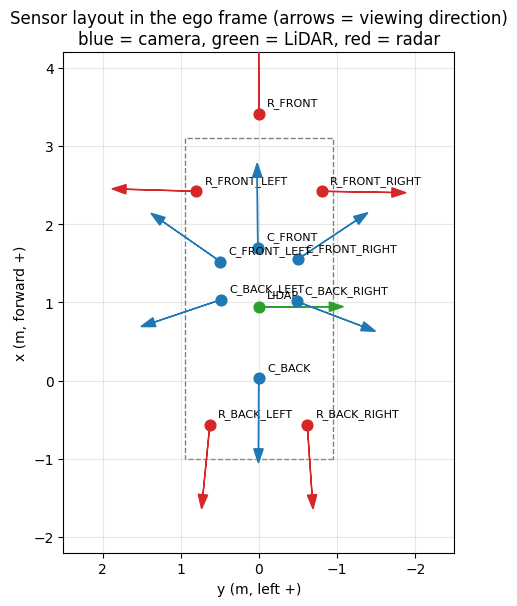

CAM_FRONT translation (m): [1.701 0.016 1.511] | rotation (quaternion): [ 0.5   -0.503  0.5   -0.497]
CAM_FRONT intrinsics K (pixels):
 [[1.2664e+03 0.0000e+00 8.1630e+02]
 [0.0000e+00 1.2664e+03 4.9150e+02]
 [0.0000e+00 0.0000e+00 1.0000e+00]]


In [11]:
COL = {"camera": "tab:blue", "lidar": "tab:green", "radar": "tab:red"}
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for ch, tok in sample["data"].items():
    sd = nusc.get("sample_data", tok)
    cs = nusc.get("calibrated_sensor", sd["calibrated_sensor_token"])
    mod = nusc.get("sensor", cs["sensor_token"])["modality"]
    axis = [0, 0, 1] if mod == "camera" else [1, 0, 0]              # optical axis vs. driving axis of the sensor
    h = Quaternion(cs["rotation"]).rotate(axis)
    x, y = cs["translation"][:2]
    ax.scatter(y, x, color=COL[mod], s=60, zorder=3)
    ax.arrow(y, x, h[1] * 0.9, h[0] * 0.9, color=COL[mod], head_width=0.12, zorder=3)
    ax.annotate(ch.replace("RADAR_", "R_").replace("CAM_", "C_").replace("LIDAR_TOP", "LIDAR"), (y, x), textcoords="offset points",
                xytext=(6, 6), fontsize=8)
ax.add_patch(plt.Rectangle((-0.95, -1.0), 1.9, 4.1, fill=False, ls="--", color="grey"))   # rough car outline (Renault Zoe ~4.1 m)
ax.set_xlim(2.5, -2.5); ax.set_ylim(-2.2, 4.2); ax.set_aspect("equal")
ax.set_xlabel("y (m, left +)"); ax.set_ylabel("x (m, forward +)")
ax.set_title("Sensor layout in the ego frame (arrows = viewing direction)\nblue = camera, green = LiDAR, red = radar")
ax.grid(alpha=0.3); plt.show()

sd = nusc.get("sample_data", sample["data"]["CAM_FRONT"])
cs = nusc.get("calibrated_sensor", sd["calibrated_sensor_token"])
print("CAM_FRONT translation (m):", np.round(cs["translation"], 3), "| rotation (quaternion):", np.round(cs["rotation"], 3))
print("CAM_FRONT intrinsics K (pixels):\n", np.round(np.array(cs["camera_intrinsic"]), 1))

Note the radars: one at the front bumper facing forward, two at the front corners pointing **sideways** (left and right), and two at the rear corners pointing backward. Each radar has a limited field of view, so the combined BEV radar map has dense wedges rather than a uniform ring. The LiDAR sits on the roof near the centre of the car; the cameras are inside the windshield and around the roof.

## 6. Ego pose and the coordinate frames

Three frames matter:

1. **Sensor frame** - raw data comes in this frame (e.g. a radar point's x, y).
2. **Ego frame** - attached to the car (x forward, y left, z up). `calibrated_sensor` converts sensor -> ego.
3. **Global frame** - the world (metres in the city map). `ego_pose` converts ego -> global, and **every sensor reading has its own ego pose** (the car moves between readings).

To merge several sweeps into one BEV we go sensor -> ego(t_i) -> global -> ego(keyframe), which is exactly what the pillar notebook does.

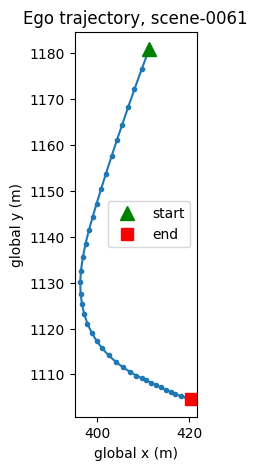

Distance driven: 91.3 m in 19.1 s (avg 4.8 m/s)

radar point  sensor frame: [12.   4.9  0. ] 
             ego frame   : [15.39  4.94  0.5 ] 
             global frame: [3.9960e+02 1.1283e+03 3.0000e-01]


In [12]:
poses = np.array([nusc.get("ego_pose", nusc.get("sample_data", s["data"]["LIDAR_TOP"])["ego_pose_token"])["translation"][:2]
                  for s in samples])
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(poses[:, 0], poses[:, 1], "-o", ms=3)
ax.plot(*poses[0], "g^", ms=10, label="start"); ax.plot(*poses[-1], "rs", ms=8, label="end")
ax.set_aspect("equal"); ax.legend(); ax.set_xlabel("global x (m)"); ax.set_ylabel("global y (m)")
ax.set_title(f"Ego trajectory, {scene['name']}"); plt.show()
print("Distance driven: %.1f m in %.1f s (avg %.1f m/s)" % (np.linalg.norm(np.diff(poses, axis=0), axis=1).sum(), ts[-1] - ts[0],
      np.linalg.norm(np.diff(poses, axis=0), axis=1).sum() / (ts[-1] - ts[0])))

# worked example: one radar point, sensor -> ego -> global
sd = nusc.get("sample_data", sample["data"]["RADAR_FRONT"])
p = RadarPointCloud.from_file(str(DATAROOT / sd["filename"])).points[:3, 0]
cs, ep = nusc.get("calibrated_sensor", sd["calibrated_sensor_token"]), nusc.get("ego_pose", sd["ego_pose_token"])
p_ego = Quaternion(cs["rotation"]).rotation_matrix @ p + np.array(cs["translation"])
p_glob = Quaternion(ep["rotation"]).rotation_matrix @ p_ego + np.array(ep["translation"])
print("\nradar point  sensor frame:", np.round(p, 2), "\n             ego frame   :", np.round(p_ego, 2), "\n             global frame:", np.round(p_glob, 1))

## 7. Cameras (6 surround-view, 1600 x 900)

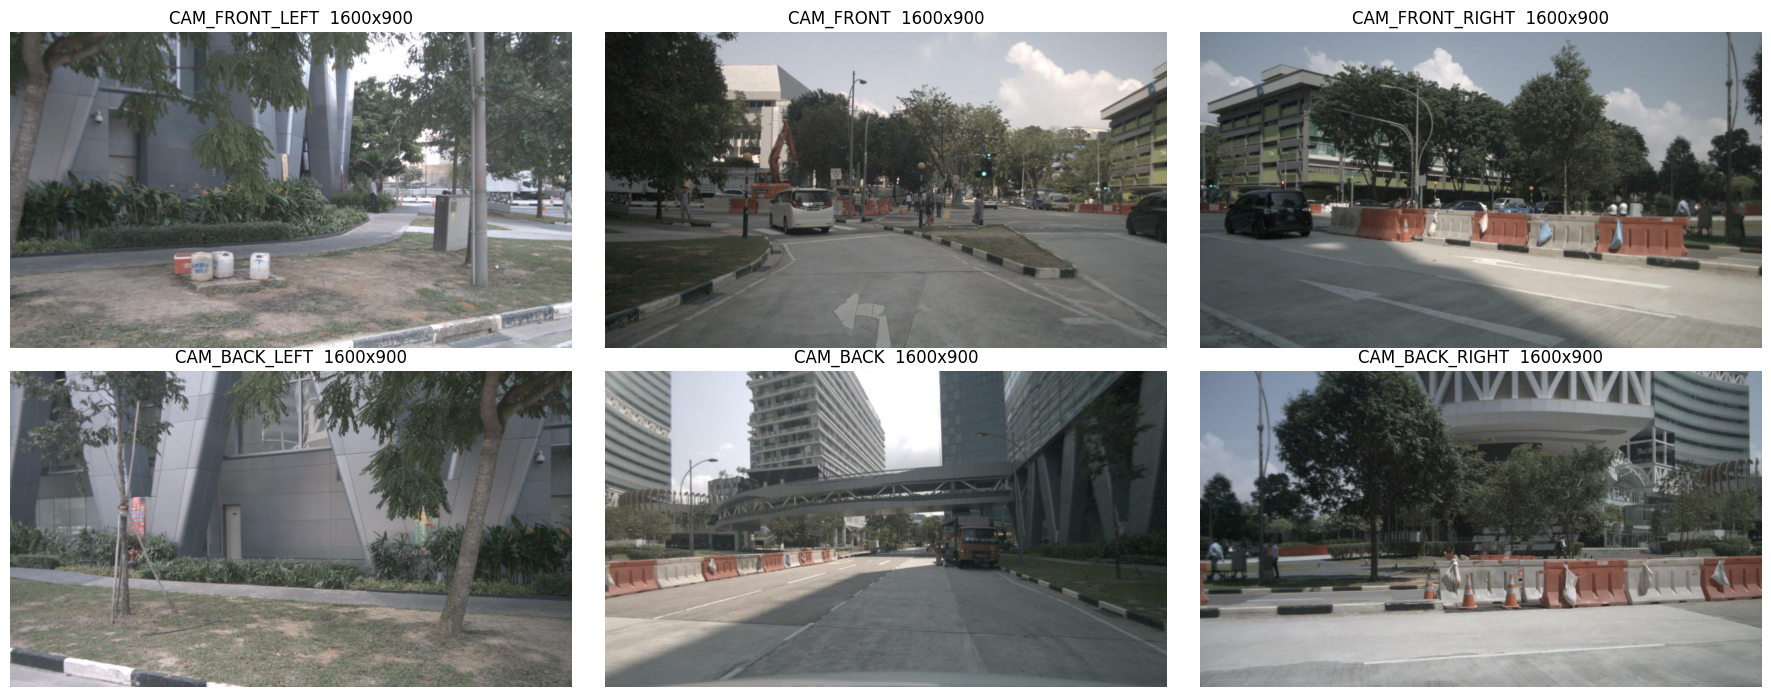

In [13]:
order = ["CAM_FRONT_LEFT", "CAM_FRONT", "CAM_FRONT_RIGHT", "CAM_BACK_LEFT", "CAM_BACK", "CAM_BACK_RIGHT"]
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for ax, ch in zip(axes.flat, order):
    img = Image.open(DATAROOT / nusc.get("sample_data", sample["data"][ch])["filename"])
    ax.imshow(img); ax.set_title(f"{ch}  {img.size[0]}x{img.size[1]}"); ax.axis("off")
plt.tight_layout(); plt.show()

Camera images carry colour, texture and text (signs, lights), but this is the modality that fails first at night and in rain. Later we will compare these views for the night scenes.

## 8. LiDAR (1 x 32-beam, 20 Hz)

A `.pcd.bin` file with 5 floats per point: x, y, z, intensity, ring index (nuScenes stores 5; the devkit keeps the first 4).

LiDAR points (rows = x, y, z, intensity): (4, 34688) -> 34,688 points in one sweep
range: 0.0 .. 99.8 m | z: -30.9 .. 15.4 m


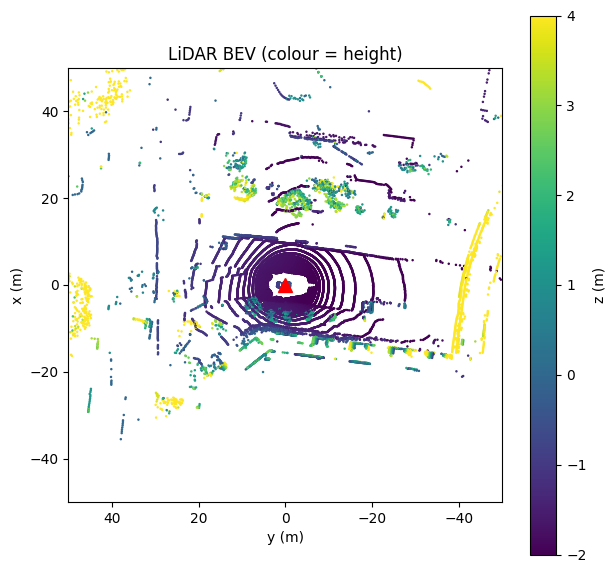

In [14]:
sd = nusc.get("sample_data", sample["data"]["LIDAR_TOP"])
pc = LidarPointCloud.from_file(str(DATAROOT / sd["filename"]))
print("LiDAR points (rows = x, y, z, intensity):", pc.points.shape, f"-> {pc.points.shape[1]:,} points in one sweep")
print("range: %.1f .. %.1f m | z: %.1f .. %.1f m" % (np.hypot(*pc.points[:2]).min(), np.hypot(*pc.points[:2]).max(), pc.points[2].min(), pc.points[2].max()))

fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(pc.points[1], pc.points[0], c=pc.points[2], s=0.6, cmap="viridis", vmin=-2, vmax=4)
ax.plot(0, 0, "r^", ms=10); ax.set_xlim(50, -50); ax.set_ylim(-50, 50); ax.set_aspect("equal")
ax.set_xlabel("y (m)"); ax.set_ylabel("x (m)"); ax.set_title("LiDAR BEV (colour = height)"); plt.colorbar(sc, label="z (m)")
plt.show()

## 8b. LiDAR in 3D - how it works, and what the colours mean

**How the sensor works:** the roof-mounted `LIDAR_TOP` unit spins around its vertical axis at 20 Hz (one full sweep per spin). It has 32 laser diodes stacked at fixed vertical angles; as the unit rotates, each beam fires thousands of infrared pulses per second and times how long each pulse takes to bounce off something and return - distance = (speed of light x time-of-flight) / 2. Combining that range with the beam's fixed elevation angle and the current rotation (azimuth) angle gives one 3D point `(x, y, z)` per pulse. Repeat that for all 32 beams over one spin and you get the ~30-40k-point sweep loaded above.

Because the elevation angles are fixed, returns fall on 32 near-horizontal rings that are dense close to the car and progressively more spread out with range and height - this is the `ring index` the raw `.pcd.bin` file stores (the devkit keeps only x, y, z, intensity).

**Reading the 3D plot below:**
- Each dot = one laser return, plotted at its real `(x, y, z)` position in the ego (car) frame.
- Colour = **height** `z` above the car by default, Viridis colormap: dark purple/blue = ground level, green = roughly 1-2 m (car roofs, pedestrians), yellow = 3 m+ (poles, signs, building facades).
- Use the dropdown to switch colour to **intensity** (Inferno colormap) - how strongly each surface reflected the laser: bright = retroreflective (road paint, metal, signs), dark = absorbent (asphalt, glass, dark clothing).
- The red diamond at the origin is the LiDAR itself (car roof); the empty disk right around it is the small blind spot under the sensor.
- Drag to orbit, scroll to zoom, hover a point for its exact x/y/z and value.

In [15]:
import plotly.graph_objects as go

x, y, z, intensity = pc.points[0], pc.points[1], pc.points[2], pc.points[3]
i_lo, i_hi = float(np.percentile(intensity, 1)), float(np.percentile(intensity, 99))

fig = go.Figure(data=[go.Scatter3d(
    x=y, y=x, z=z,                      # plot-x = y (left+), plot-y = x (forward+): matches the BEV plot above
    mode="markers",
    marker=dict(size=1.6, color=z, colorscale="Viridis", cmin=-2, cmax=4, opacity=0.85,
                colorbar=dict(title="height z (m)")),
    customdata=np.stack([x, y, z, intensity], axis=-1),
    hovertemplate="x=%{customdata[0]:.1f}m  y=%{customdata[1]:.1f}m  z=%{customdata[2]:.1f}m"
                  "<br>intensity=%{customdata[3]:.0f}<extra></extra>",
    name="LiDAR points",
)])
fig.add_trace(go.Scatter3d(x=[0], y=[0], z=[0], mode="markers",
                            marker=dict(size=7, color="red", symbol="diamond"), name="LiDAR (ego)"))

fig.update_layout(
    scene=dict(xaxis=dict(title="y (m, left +)", range=[40, -40]),
               yaxis=dict(title="x (m, forward +)", range=[-40, 40]),
               zaxis=dict(title="z (m, up)", range=[-3, 10]),
               aspectmode="manual", aspectratio=dict(x=2, y=2, z=0.35),
               camera=dict(eye=dict(x=0, y=-1.7, z=1.0))),
    title=f"LiDAR sweep in 3D, {pc.points.shape[1]:,} points - colour = height",
    updatemenus=[dict(direction="down", x=0.0, y=1.0, xanchor="left", yanchor="top", buttons=[
        dict(label="Colour: height (z)", method="restyle",
             args=[{"marker.color": [z], "marker.colorscale": "Viridis", "marker.cmin": -2, "marker.cmax": 4,
                    "marker.colorbar.title": "height z (m)"}, [0]]),
        dict(label="Colour: intensity", method="restyle",
             args=[{"marker.color": [intensity], "marker.colorscale": "Inferno", "marker.cmin": i_lo, "marker.cmax": i_hi,
                    "marker.colorbar.title": "intensity"}, [0]]),
    ])],
    width=880, height=680, margin=dict(l=0, r=0, t=40, b=0),
)
fig.show()

## 9. Radar (5 x Continental ARS 408, 77 GHz, ~13 Hz)

Each file is a small point cloud with **18 fields per point**. Here is one radar loaded with *no filtering*, as a table.

In [16]:
FIELDS = "x y z dyn_prop id rcs vx vy vx_comp vy_comp is_quality_valid ambig_state x_rms y_rms invalid_state pdh0 vx_rms vy_rms".split()
sd = nusc.get("sample_data", sample["data"]["RADAR_FRONT"])
raw = RadarPointCloud.from_file(str(DATAROOT / sd["filename"]), invalid_states=list(range(19)),
                                dynprop_states=list(range(8)), ambig_states=list(range(5)))
df = pd.DataFrame(raw.points.T, columns=FIELDS)
print("RADAR_FRONT raw:", df.shape[0], "points x", df.shape[1], "fields")
display(df.head(8).round(2))

RADAR_FRONT raw: 125 points x 18 fields


,x,y,z,dyn_prop,id,rcs,vx,vy,vx_comp,vy_comp,is_quality_valid,ambig_state,x_rms,y_rms,invalid_state,pdh0,vx_rms,vy_rms
0,3.6,4.3,0.0,1.0,0.0,4.0,-6.25,-0.25,-0.07,-0.09,1.0,3.0,19.0,19.0,10.0,3.0,18.0,3.0
1,6.4,6.5,0.0,1.0,1.0,-2.0,-6.00,-0.25,0.05,0.05,1.0,3.0,19.0,19.0,9.0,3.0,17.0,3.0
2,12.0,4.9,0.0,1.0,2.0,9.0,-6.25,-0.50,-0.15,-0.06,1.0,3.0,19.0,19.0,0.0,1.0,16.0,3.0
3,11.6,-8.5,0.0,0.0,3.0,12.5,1.00,0.00,4.66,-3.41,1.0,3.0,19.0,20.0,0.0,1.0,17.0,3.0
4,10.0,-11.1,0.0,1.0,4.0,1.0,-6.75,-0.50,-0.03,0.04,1.0,3.0,19.0,19.0,0.0,1.0,18.0,3.0
5,12.4,-9.9,0.0,0.0,5.0,-2.0,1.00,0.00,4.37,-3.49,1.0,3.0,20.0,21.0,0.0,1.0,17.0,3.0
6,16.2,-0.9,0.0,1.0,6.0,5.5,-6.50,-0.75,-0.22,0.01,1.0,3.0,19.0,19.0,0.0,1.0,16.0,3.0
7,16.4,3.1,0.0,0.0,7.0,12.5,-2.75,0.00,3.39,0.64,1.0,3.0,19.0,19.0,0.0,1.0,16.0,3.0


**What the fields mean** (from the devkit documentation)

| Field | Meaning |
|---|---|
| `x y z` | Position in the sensor frame (m). `z` is unreliable (these radars barely resolve elevation). |
| `rcs` | Radar cross section in dBsm: how strongly the object reflects. Big metal things = high. |
| `vx vy` | Velocity from the radar, **not** corrected for the car's own motion. |
| `vx_comp vy_comp` | Same velocity **compensated for ego motion**. Use these: a parked car reads ~0. They are radial (along the line of sight). |
| `dyn_prop` | Motion class: 0 moving, 1 stationary, 2 oncoming, 3 stationary candidate, 4 unknown, 5 crossing stationary, 6 crossing moving, 7 stopped. |
| `invalid_state` | Cluster validity: 0 = valid; other codes = low RCS, near-field artefact, multipath/mirror, outside FOV, harmonics... |
| `ambig_state` | Doppler ambiguity: 0 invalid, 1 ambiguous, 2 staggered ramp, 3 unambiguous, 4 stationary candidates. |
| `pdh0` | False-alarm probability of the cluster (1 = <25% ... 7 = up to 100%). |
| `*_rms` | Uncertainty estimates for position and velocity. |

By default the devkit **keeps only `invalid_state = 0` and `ambig_state = 3`**, which throws away roughly half of the points. That filtering is a real design choice for us.

,sensor,raw_points,kept_by_default_filter
0,RADAR_FRONT,125,69
1,RADAR_FRONT_LEFT,48,14
2,RADAR_FRONT_RIGHT,80,26
3,RADAR_BACK_LEFT,125,62
4,RADAR_BACK_RIGHT,125,70


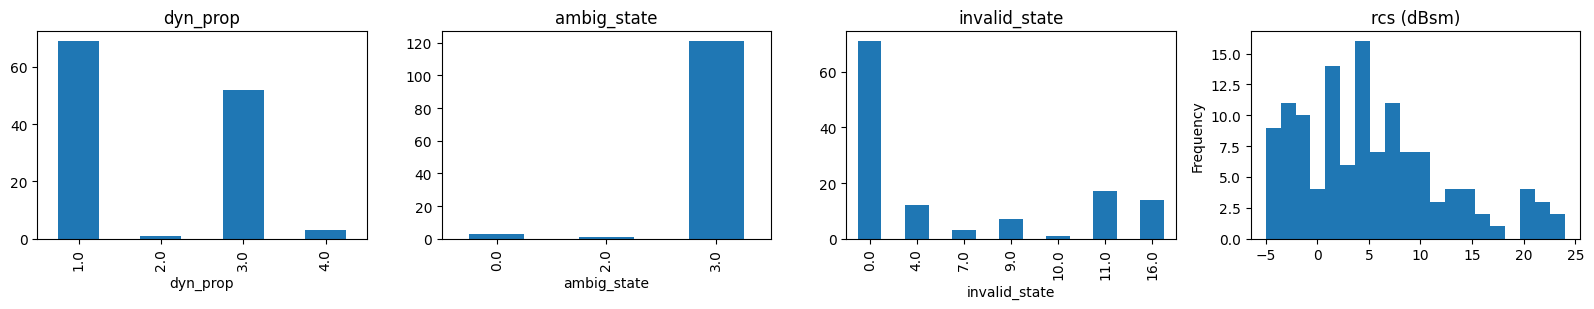

(histograms are for RADAR_BACK_RIGHT, last sensor in the loop)


In [17]:
rows = []
for ch in [c for c in sample["data"] if c.startswith("RADAR")]:
    sd = nusc.get("sample_data", sample["data"][ch])
    raw = RadarPointCloud.from_file(str(DATAROOT / sd["filename"]), invalid_states=list(range(19)),
                                    dynprop_states=list(range(8)), ambig_states=list(range(5)))
    kept = RadarPointCloud.from_file(str(DATAROOT / sd["filename"]))
    rows.append(dict(sensor=ch, raw_points=raw.points.shape[1], kept_by_default_filter=kept.points.shape[1]))
display(pd.DataFrame(rows))

d = pd.DataFrame(raw.points.T, columns=FIELDS)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
d["dyn_prop"].value_counts().sort_index().plot.bar(ax=axes[0], title="dyn_prop"); d["ambig_state"].value_counts().sort_index().plot.bar(ax=axes[1], title="ambig_state")
d["invalid_state"].value_counts().sort_index().plot.bar(ax=axes[2], title="invalid_state"); d["rcs"].plot.hist(bins=20, ax=axes[3], title="rcs (dBsm)")
plt.tight_layout(); plt.show()
print("(histograms are for RADAR_BACK_RIGHT, last sensor in the loop)")

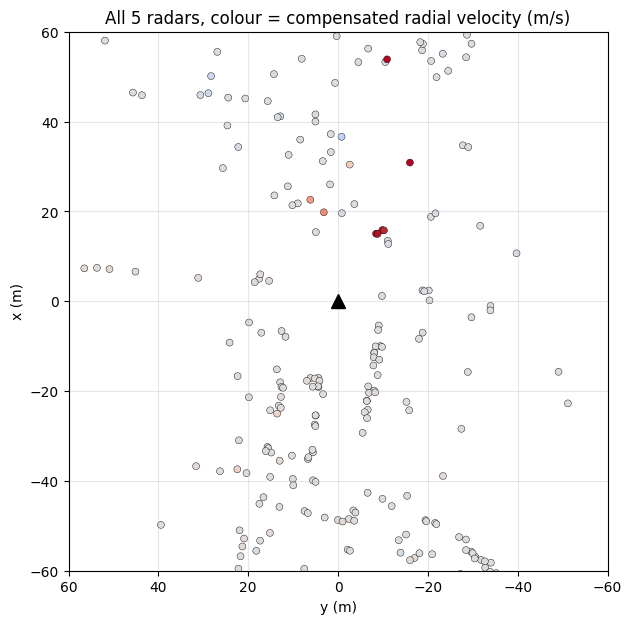

Total kept radar points in this keyframe: 241 | LiDAR points: 34688


In [18]:
RADARS = [c for c in sample["data"] if c.startswith("RADAR")]
fig, ax = plt.subplots(figsize=(7, 7))
for ch in RADARS:
    d = load_radar(nusc, sample, ch)
    ax.scatter(d["y"], d["x"], c=d["v_radial"], cmap="coolwarm", vmin=-6, vmax=6, s=25, edgecolor="k", linewidth=0.3)
ax.plot(0, 0, "k^", ms=10); ax.set_xlim(60, -60); ax.set_ylim(-60, 60); ax.set_aspect("equal")
ax.set_xlabel("y (m)"); ax.set_ylabel("x (m)"); ax.set_title("All 5 radars, colour = compensated radial velocity (m/s)")
ax.grid(alpha=0.3); plt.show()
print("Total kept radar points in this keyframe:", sum(len(load_radar(nusc, sample, c)["x"]) for c in RADARS), "| LiDAR points:", pc.points.shape[1])

## 10. 3D box annotations

Every keyframe has hand-labelled 3D boxes (`sample_annotation`). Each box links to an **instance** (one physical object over time), a **category**,
**attributes** (e.g. `vehicle.moving`) and a **visibility** level. Boxes also record how many LiDAR and radar points fall inside them.

In [19]:
ins2cat = {i["token"]: nusc.get("category", i["category_token"])["name"] for i in nusc.instance}
vis = {v["token"]: v["description"] for v in nusc.visibility}

rows = []
for tok in sample["anns"][:12]:
    a = nusc.get("sample_annotation", tok)
    rows.append(dict(category=ins2cat[a["instance_token"]], size_wlh_m=np.round(a["size"], 1).tolist(),
                     xyz_global=np.round(a["translation"], 0).tolist(), lidar_pts=a["num_lidar_pts"], radar_pts=a["num_radar_pts"],
                     visibility=vis[a["visibility_token"]],
                     attributes=[nusc.get("attribute", t)["name"] for t in a["attribute_tokens"]]))
display(pd.DataFrame(rows))

,category,size_wlh_m,xyz_global,lidar_pts,radar_pts,visibility,attributes
0,human.pedestrian.adult,"[0.6, 0.7, 1.6]","[373.0, 1130.0, 1.0]",1,0,visibility of whole object is between 0 and 40%,[pedestrian.standing]
1,human.pedestrian.adult,"[0.8, 0.8, 1.7]","[376.0, 1148.0, 1.0]",3,0,visibility of whole object is between 60 and 80%,[pedestrian.moving]
2,vehicle.car,"[2.0, 4.6, 1.6]","[354.0, 1132.0, 1.0]",10,0,visibility of whole object is between 60 and 80%,[vehicle.stopped]
3,human.pedestrian.adult,"[0.8, 0.8, 1.6]","[379.0, 1164.0, 1.0]",2,0,visibility of whole object is between 80 and 100%,[pedestrian.moving]
4,vehicle.bicycle,"[0.7, 1.8, 1.7]","[373.0, 1129.0, 1.0]",3,0,visibility of whole object is between 40 and 60%,[cycle.with_rider]
5,human.pedestrian.adult,"[0.7, 0.7, 1.8]","[376.0, 1146.0, 1.0]",11,0,visibility of whole object is between 60 and 80%,[pedestrian.moving]
6,human.pedestrian.construction_worker,"[0.6, 0.7, 1.8]","[393.0, 1113.0, 1.0]",0,0,visibility of whole object is between 0 and 40%,[pedestrian.standing]
7,vehicle.truck,"[2.5, 6.5, 3.2]","[412.0, 1092.0, 2.0]",18,0,visibility of whole object is between 60 and 80%,[vehicle.stopped]
8,vehicle.motorcycle,"[1.2, 2.1, 1.9]","[356.0, 1125.0, 1.0]",2,0,visibility of whole object is between 40 and 60%,[cycle.with_rider]
9,human.pedestrian.adult,"[0.7, 0.9, 1.8]","[387.0, 1112.0, 1.0]",3,0,visibility of whole object is between 60 and 80%,[pedestrian.moving]


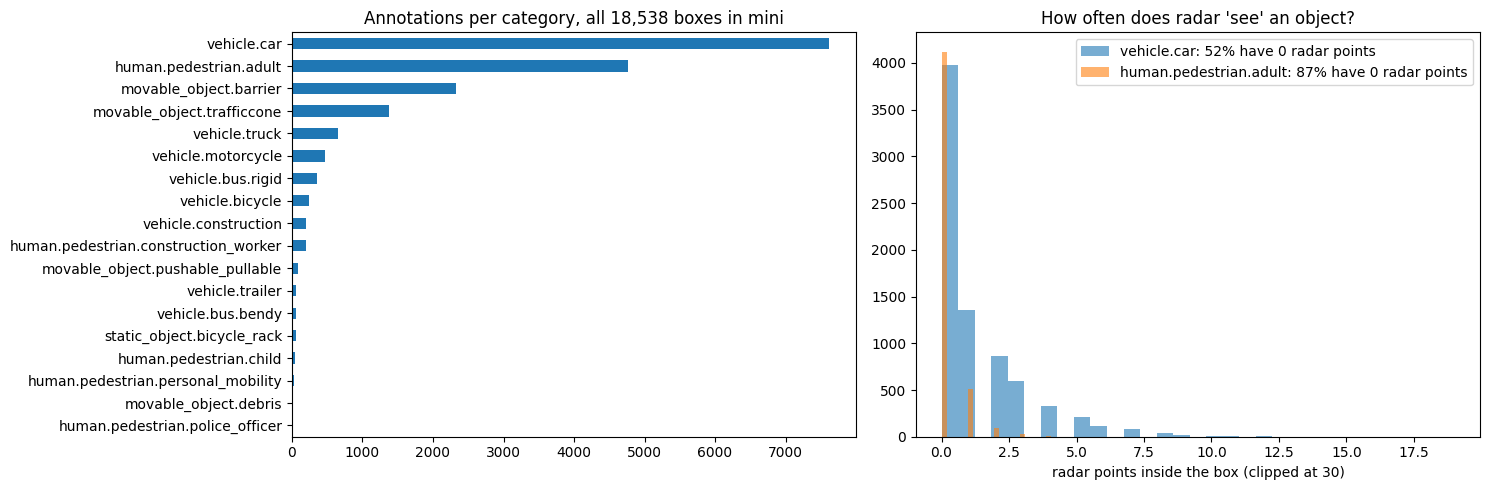

In [20]:
counts = collections.Counter(ins2cat[a["instance_token"]] for a in nusc.sample_annotation)
top = pd.Series(counts).sort_values(ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top.plot.barh(ax=axes[0], title=f"Annotations per category, all {len(nusc.sample_annotation):,} boxes in mini")

for cat, colr in [("vehicle.car", "tab:blue"), ("human.pedestrian.adult", "tab:orange")]:
    n = [a["num_radar_pts"] for a in nusc.sample_annotation if ins2cat[a["instance_token"]] == cat]
    axes[1].hist(np.clip(n, 0, 30), bins=31, alpha=0.6, label=f"{cat}: {np.mean(np.array(n) == 0):.0%} have 0 radar points", color=colr)
axes[1].set_xlabel("radar points inside the box (clipped at 30)"); axes[1].legend(); axes[1].set_title("How often does radar 'see' an object?")
plt.tight_layout(); plt.show()

This second plot matters for our paper. In mini, **52% of annotated cars and 87% of annotated pedestrians contain zero radar points** (see the legend; these are all boxes at any distance, so far-away objects count too). Radar is sparse and small or weakly reflecting objects are often missed. Radar-led captioning will therefore need the camera for many objects, which is exactly the role of the gated camera branch.

In [21]:
# ground-truth velocity is derived from consecutive annotations of the same instance (global frame, m/s)
speeds = []
for tok in sample["anns"]:
    v = nusc.box_velocity(tok)
    if not np.isnan(v).any():
        speeds.append((ins2cat[nusc.get("sample_annotation", tok)["instance_token"]], round(float(np.linalg.norm(v[:2])), 2)))
print("Ground-truth speeds in this keyframe (category, m/s), fastest first:")
for c, s in sorted(speeds, key=lambda t: -t[1])[:8]:
    print(f"  {c:32s} {s:5.2f} m/s")

Ground-truth speeds in this keyframe (category, m/s), fastest first:
  vehicle.car                       7.83 m/s
  vehicle.car                       6.51 m/s
  vehicle.truck                     6.33 m/s
  vehicle.car                       3.51 m/s
  human.pedestrian.adult            1.74 m/s
  human.pedestrian.adult            1.58 m/s
  human.pedestrian.adult            1.57 m/s
  human.pedestrian.adult            1.46 m/s


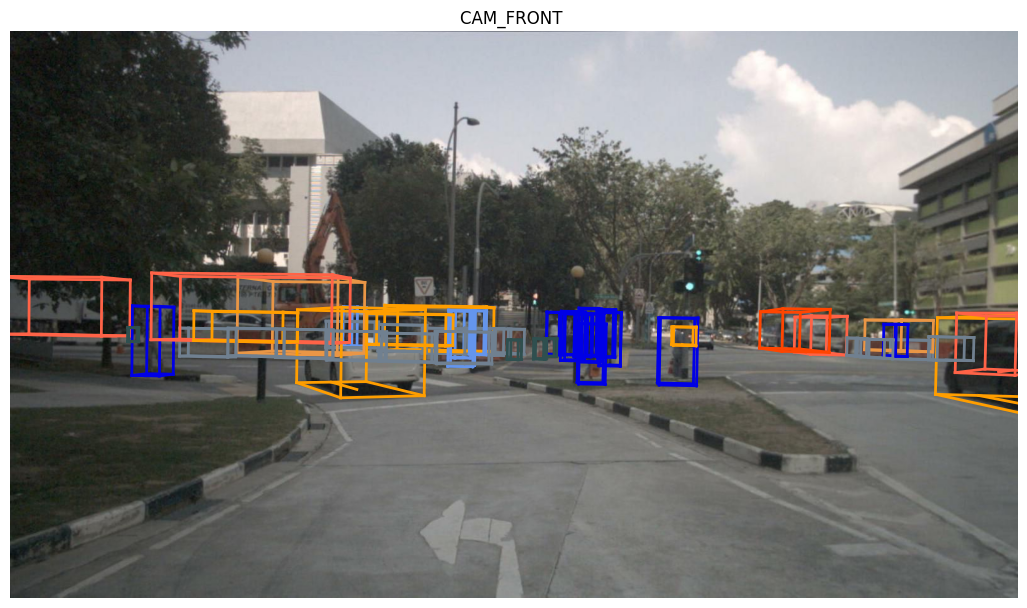

In [22]:
plt.figure(figsize=(13, 7.5))
nusc.render_sample_data(sample["data"]["CAM_FRONT"], with_anns=True, ax=plt.gca())      # devkit renderer (calls plt.show itself)

The boxes are projected from 3D into the image. Notice that boxes are drawn for objects **hidden behind others or the barrier** (low visibility): annotators labelled everything using LiDAR and all cameras, so 'visible in the camera' and 'annotated' are not the same thing. Colours are categories (orange = vehicles, blue = pedestrians, and so on).

## 11. LiDAR + radar + boxes in one picture

Grey = LiDAR, coloured dots = radar. Boxes are **green if at least one radar point falls inside**, red if radar missed the object.

(Expect many red boxes: distant, small or static things such as barriers, cones and parked cars. Also notice that most radar dots sit on **unannotated clutter** like buildings and poles, not on labelled objects.)

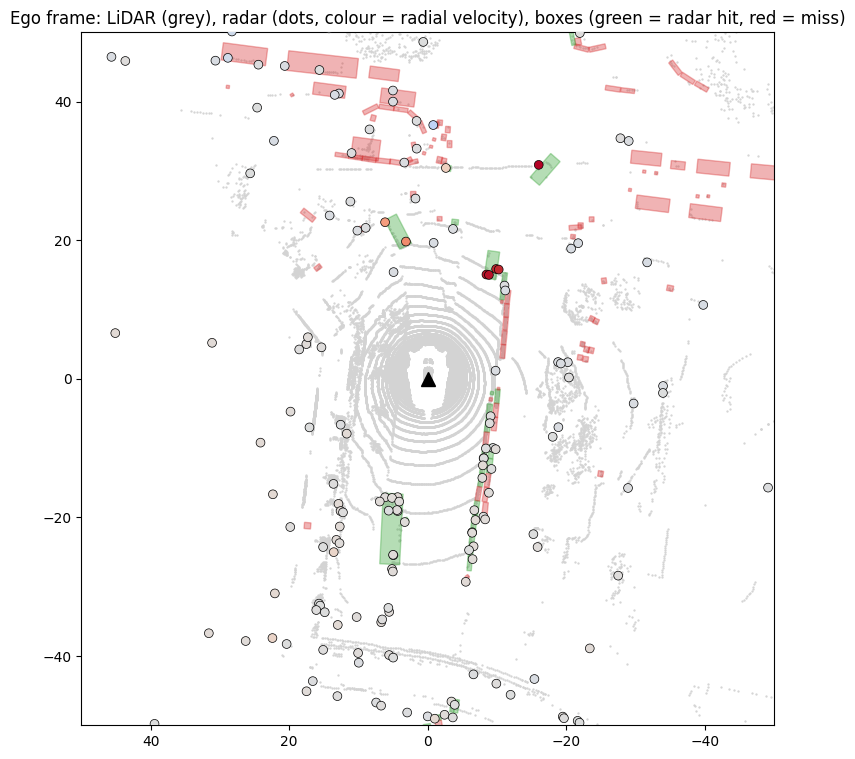

In [23]:
lidar_tok = sample["data"]["LIDAR_TOP"]
sd = nusc.get("sample_data", lidar_tok)
cs = nusc.get("calibrated_sensor", sd["calibrated_sensor_token"])
R, t = Quaternion(cs["rotation"]).rotation_matrix, np.array(cs["translation"])
lp = R @ LidarPointCloud.from_file(str(DATAROOT / sd["filename"])).points[:3] + t[:, None]      # LiDAR -> ego

_, boxes, _ = nusc.get_sample_data(lidar_tok, use_flat_vehicle_coordinates=False)                # boxes in LiDAR frame
for b in boxes:
    b.rotate(Quaternion(cs["rotation"])); b.translate(t)                                          # -> ego frame

fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(lp[1], lp[0], s=0.4, c="lightgrey", zorder=1)
for b in boxes:
    n_radar = nusc.get("sample_annotation", b.token)["num_radar_pts"]
    corners = b.bottom_corners()
    ax.fill(corners[1], corners[0], alpha=0.35, color="tab:green" if n_radar > 0 else "tab:red", zorder=2)
for ch in RADARS:
    d = load_radar(nusc, sample, ch)
    ax.scatter(d["y"], d["x"], c=d["v_radial"], cmap="coolwarm", vmin=-6, vmax=6, s=40, edgecolor="k", linewidth=0.5, zorder=4)
ax.plot(0, 0, "k^", ms=10, zorder=5); ax.set_xlim(50, -50); ax.set_ylim(-50, 50); ax.set_aspect("equal")
ax.set_title("Ego frame: LiDAR (grey), radar (dots, colour = radial velocity), boxes (green = radar hit, red = miss)")
plt.show()

## 12. Maps, logs, and weather / lighting

`log` describes the physical recording (city, date, car). There is **no weather field anywhere in nuScenes**; the only clue is the free-text scene `description`,
so our weather buckets have to come from keywords like *night* and *rain*.

In [24]:
def bucket(desc):
    d = desc.lower()
    night, rain = "night" in d, "rain" in d
    return "night+rain" if night and rain else "night" if night else "rain" if rain else "clear-day"

rows = []
for s in nusc.scene:
    lg = nusc.get("log", s["log_token"])
    rows.append(dict(scene=s["name"], city=lg["location"], date=lg["date_captured"], description=s["description"], bucket=bucket(s["description"])))
df = pd.DataFrame(rows); display(df)
print(df.bucket.value_counts().to_string())

,scene,city,date,description,bucket
0,scene-0061,singapore-onenorth,2018-07-24,"Parked truck, construction, intersection, turn left, following a van",clear-day
1,scene-0103,boston-seaport,2018-08-01,"Many peds right, wait for turning car, long bike rack left, cyclist",clear-day
2,scene-0553,boston-seaport,2018-08-28,"Wait at intersection, bicycle, large truck, peds crossing crosswal...",clear-day
3,scene-0655,boston-seaport,2018-08-27,"Parking lot, parked cars, jaywalker, bendy bus, gardening vehicles",clear-day
4,scene-0757,boston-seaport,2018-08-30,"Arrive at busy intersection, bus, wait at intersection, bicycle, peds",clear-day
5,scene-0796,singapore-queenstown,2018-10-02,"Scooter, peds on sidewalk, bus, cars, truck, fake construction wor...",clear-day
6,scene-0916,singapore-queenstown,2018-10-08,"Parking lot, bicycle rack, parked bicycles, bus, many peds, parked...",clear-day
7,scene-1077,singapore-hollandvillage,2018-11-21,"Night, big street, bus stop, high speed, construction vehicle",night
8,scene-1094,singapore-hollandvillage,2018-11-21,"Night, after rain, many peds, PMD, ped with bag, jaywalker, truck,...",night+rain
9,scene-1100,singapore-hollandvillage,2018-11-21,"Night, peds in sidewalk, peds cross crosswalk, scooter, PMD, diffi...",night


bucket
clear-day     7
night         2
night+rain    1


Only 3 of the 10 mini scenes are night and just **one** mentions rain, and even that is *"after rain"* (wet road, maybe no rain falling). Free-text keyword matching is noisy: some scenes may be rainy without saying so. Later we should verify buckets by looking at the images, and report bucket sizes honestly.

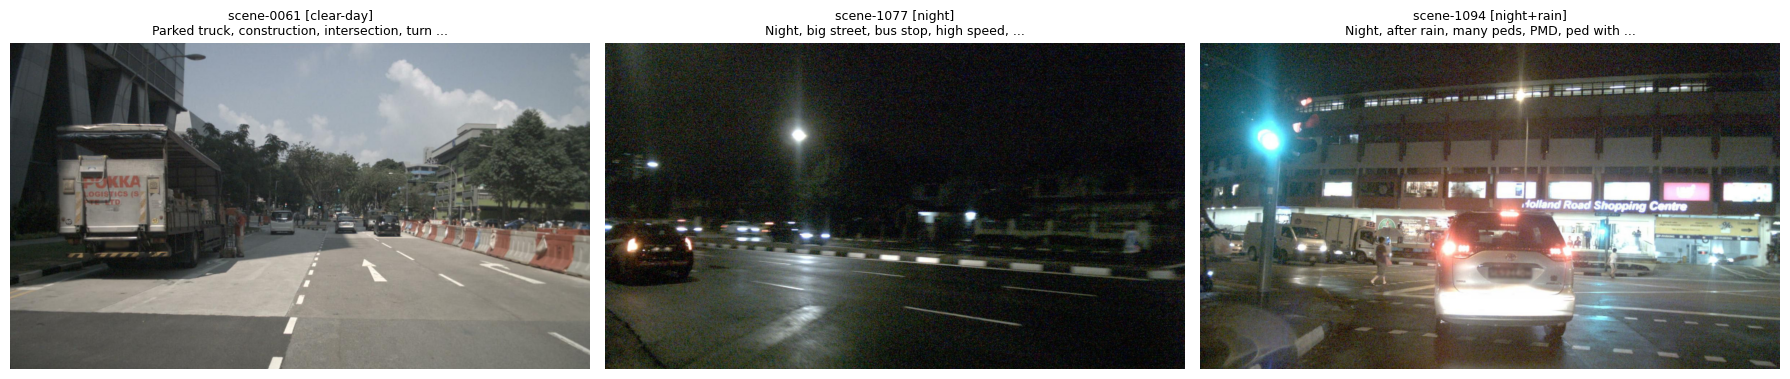

map table:


,category,filename
0,semantic_prior,maps/53992ee3023e5494b90c316c183be829.png
1,semantic_prior,maps/36092f0b03a857c6a3403e25b4b7aab3.png
2,semantic_prior,maps/93406b464a165eaba6d9de76ca09f5da.png
3,semantic_prior,maps/37819e65e09e5547b8a3ceaefba56bb2.png


one map image: (15856, 20250) px | mode L (category 'semantic_prior': a city-wide raster mask; the vector map with lanes is a separate 'map expansion' download)


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, name in zip(axes, ["scene-0061", "scene-1077", "scene-1094"]):
    sc = next(s for s in nusc.scene if s["name"] == name)
    smp = nusc.get("sample", sc["first_sample_token"])
    ax.imshow(Image.open(DATAROOT / nusc.get("sample_data", smp["data"]["CAM_FRONT"])["filename"]))
    desc = sc["description"]
    ax.set_title(f"{name} [{bucket(desc)}]\n{desc if len(desc) <= 48 else desc[:47].rsplit(' ', 1)[0] + ' ...'}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

print("map table:"); display(pd.DataFrame(nusc.map)[["category", "filename"]])
m = Image.open(DATAROOT / nusc.map[0]["filename"]); print("one map image:", m.size, "px | mode", m.mode, "(category 'semantic_prior': a city-wide raster mask; the vector map with lanes is a separate 'map expansion' download)")

## 13. Language data: nuScenes-QA

Questions are attached to keyframes by `sample_token`. The full file covers all of nuScenes; we filter it to our mini samples.

In [26]:
qa = json.load(open(ROOT / "data" / "nuscenes_qa" / "NuScenes_val_questions.json"))
qs = pd.DataFrame(qa["questions"])
mini_tokens = {s["token"] for s in nusc.sample}
qm = qs[qs.sample_token.isin(mini_tokens)]
print(f"val file: {len(qs):,} questions | on mini samples: {len(qm):,} over {qm.sample_token.nunique()} keyframes")
display(qm.groupby(["template_type", "num_hop"]).size().unstack(fill_value=0))
print("Most common answers:", qm.answer.value_counts().head(8).to_dict())

val file: 83,337 questions | on mini samples: 2,532 over 162 keyframes


num_hop,0,1
template_type,,
comparison,50,404
count,234,260
exist,331,350
object,125,418
status,161,199


Most common answers: {'yes': 636, 'no': 499, 'pedestrian': 173, 'car': 165, 'moving': 115, '1': 104, '0': 90, 'parked': 86}


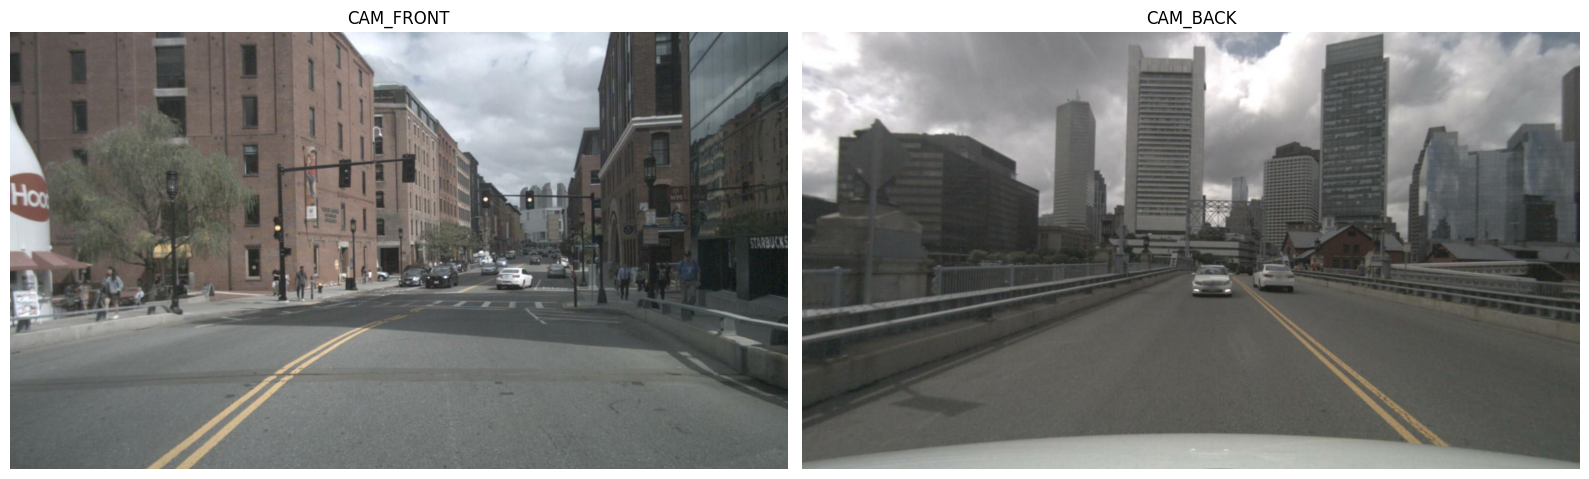

[count      hop=1] There is a not standing pedestrian; what number of things are to the front left of it?  ->  5
[count      hop=1] There is a not standing pedestrian; what number of things are to the back right of it?  ->  7
[exist      hop=0] Are any cars visible?  ->  yes
[exist      hop=1] Are there any moving cars to the back left of me?  ->  no
[exist      hop=1] Are there any other cars that in the same status as the car to the front left of the not standing pedestrian?  ->  yes


In [27]:
tok = qm.sample_token.iloc[0]
smp = nusc.get("sample", tok)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(Image.open(DATAROOT / nusc.get("sample_data", smp["data"]["CAM_FRONT"])["filename"])); axes[0].axis("off"); axes[0].set_title("CAM_FRONT")
axes[1].imshow(Image.open(DATAROOT / nusc.get("sample_data", smp["data"]["CAM_BACK"])["filename"])); axes[1].axis("off"); axes[1].set_title("CAM_BACK")
plt.tight_layout(); plt.show()
for _, r in qm[qm.sample_token == tok].head(10).iterrows():
    print(f"[{r.template_type:10s} hop={r.num_hop}] {r.question}  ->  {r.answer}")

Observe: the questions are template-generated from the ground-truth boxes (*"Are there any moving cars to the back of me?"*), so they test counting, existence and spatial relations, and many depend on **motion status** (`moving` / `parked`), which is exactly what Doppler could help with. They do not use weather or radar, and answers about appearance (colour, status) need the camera.

## 14. Trace one radar file back to its scene

Putting the whole chain together: file -> sample_data -> sample -> scene -> log.

In [28]:
rfile = next((DATAROOT / "samples" / "RADAR_FRONT_LEFT").iterdir())
sd = next(s for s in nusc.sample_data if s["filename"].endswith(rfile.name))
cs, ep = nusc.get("calibrated_sensor", sd["calibrated_sensor_token"]), nusc.get("ego_pose", sd["ego_pose_token"])
smp = nusc.get("sample", sd["sample_token"]); sc = nusc.get("scene", smp["scene_token"]); lg = nusc.get("log", sc["log_token"])

print("file          :", rfile.name)
print("sample_data   :", sd["token"], "| key frame:", sd["is_key_frame"], "| prev sweep:", bool(sd["prev"]), "| next sweep:", bool(sd["next"]))
print("sensor        :", nusc.get("sensor", cs["sensor_token"])["channel"], "at", np.round(cs["translation"], 2), "in the ego frame")
print("ego_pose      : t =", round(ep["timestamp"] * 1e-6, 3), "s, global xy =", np.round(ep["translation"][:2], 1))
print("sample        :", smp["token"], "->", len(smp["anns"]), "annotated objects")
print("scene         :", sc["name"], "-", sc["description"])
print("log           :", lg["logfile"], "|", lg["location"], "|", lg["date_captured"])

file          : n008-2018-08-01-15-16-36-0400__RADAR_FRONT_LEFT__1533151603526348.pcd
sample_data   : 24ba6892937946f28e64a26febe81686 | key frame: True | prev sweep: False | next sweep: True
sensor        : RADAR_FRONT_LEFT at [2.42 0.8  0.78] in the ego frame
ego_pose      : t = 1533151603.526 s, global xy = [ 600.  1647.6]
sample        : 3e8750f331d7499e9b5123e9eb70f2e2 -> 23 annotated objects
scene         : scene-0103 - Many peds right, wait for turning car, long bike rack left, cyclist
log           : n008-2018-08-01-15-16-36-0400 | boston-seaport | 2018-08-01


## Summary: what Paper 1 uses

| Data | Where | Used for |
|---|---|---|
| Radar points (`samples/RADAR_*`, `sweeps/RADAR_*`) | `sample_data` -> file | Radar-led BEV encoder (primary input) |
| Camera images (`samples/CAM_*`) | `sample_data` -> file | Gated secondary input |
| Ego pose + calibration | `ego_pose`, `calibrated_sensor` | Multi-sweep alignment, sensor -> ego -> global |
| 3D boxes + velocity | `sample_annotation` | Detection proxy targets, ground-truth captions and Doppler QA |
| Scene description + log | `scene`, `log` | Weather / lighting buckets |
| nuScenes-QA | `NuScenes_*_questions.json` | VQA training and evaluation |
| LiDAR | `samples/LIDAR_TOP` | Not an input to our model; useful for visualization and the BEV-LLM baseline |